# Etapa 6: Lógica Fuzzy (Mamdani) sobre a rede Bayesiana
Censo Escolar 2025, escolas do Amazonas. Fechamos o pipeline com um sistema fuzzy que recebe a probabilidade da rede Bayesiana da Etapa 5 e devolve uma **urgência de apoio** de 0 a 100, em vez de um simples "tem / não tem" decidido pelo limiar de 0,5.

A pergunta prática continua a da Etapa 1: a escola tem infraestrutura digital básica (`infra_digital_basica`)? Agora a decisão é a de um gestor da rede: **qual escola deve receber apoio primeiro, e com que grau de certeza?**

**Como a Etapa 5 entra aqui.** O gestor sabe, antes de visitar a escola, só o que está no cadastro: a localização (`TP_LOCALIZACAO`), a rede de ensino (`TP_DEPENDENCIA`) e se ela depende de gerador (`IN_ENERGIA_GERADOR_FOSSIL`). Esses três valores são a **evidência**. A rede Bayesiana soma sobre laboratório e biblioteca, que não são observados, e responde $P(\text{infra} \mid \text{evidência})$ com a inferência por enumeração que já implementamos. Essa probabilidade é a entrada do sistema fuzzy.

O código está em `fuzzy.py` (usa direto o `inferencia_enumeracao.py` da Etapa 5). Para rodar fora do notebook: `python fuzzy.py dados_etapa1.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from skfuzzy import control as ctrl
import skfuzzy as fuzz

from fuzzy import (ALVO, EVIDENCIA_PADRAO, REGRAS_EM_TEXTO, calcular_urgencia, comparar_decisoes,
                   construir_sistema, executar, grafico_curva, grafico_pertinencia, validacao_cruzada)

np.random.seed(42)   # nada aqui é aleatório (as dobras usam random_state=42), mas fica registrado
df, rede, sistema, variaveis, tabela = executar("dados_etapa1.csv", EVIDENCIA_PADRAO)
risco, confianca, urgencia = variaveis
print(f"{len(df)} escolas | evidência: {EVIDENCIA_PADRAO}")

5562 escolas | evidência: ['TP_LOCALIZACAO', 'TP_DEPENDENCIA', 'IN_ENERGIA_GERADOR_FOSSIL']


## 1. Variáveis linguísticas
Usamos três variáveis, duas de entrada e uma de saída.

| Variável | Papel | Universo | Termos | De onde vem |
|---|---|---|---|---|
| `risco` | entrada | 0 a 1 | baixo, médio, alto | $P(\text{infra} = 0 \mid \text{evidência})$, calculada pela rede da Etapa 5 |
| `confianca` | entrada | 0 a 100 | baixa, alta | número de escolas do Censo com a mesma evidência, limitado a 100 |
| `urgencia` | saída | 0 a 100 | baixa, média, alta | decisão do sistema |

**Por que a `confianca`?** A Etapa 5 mostrou que algumas linhas das CPTs se apoiam em poucas escolas (N = 8, 18, 32). Uma probabilidade de 0,70 calculada com 8 escolas não merece o mesmo peso de uma calculada com 700, e a probabilidade sozinha esconde essa diferença. Colocar o N como variável linguística faz o sistema "desconfiar" quando há pouco dado.

Esse número é uma heurística de suporte amostral, não uma probabilidade de acerto nem um intervalo de confiança. Quando há variáveis ocultas, ele não resume toda a incerteza das CPTs.

## 2. Funções de pertinência triangulares
Cada termo é triangular. Os conjuntos cobrem os universos, mas as pertinências de risco e urgência somam entre 0,5 e 1. Mamdani não exige soma igual a 1.

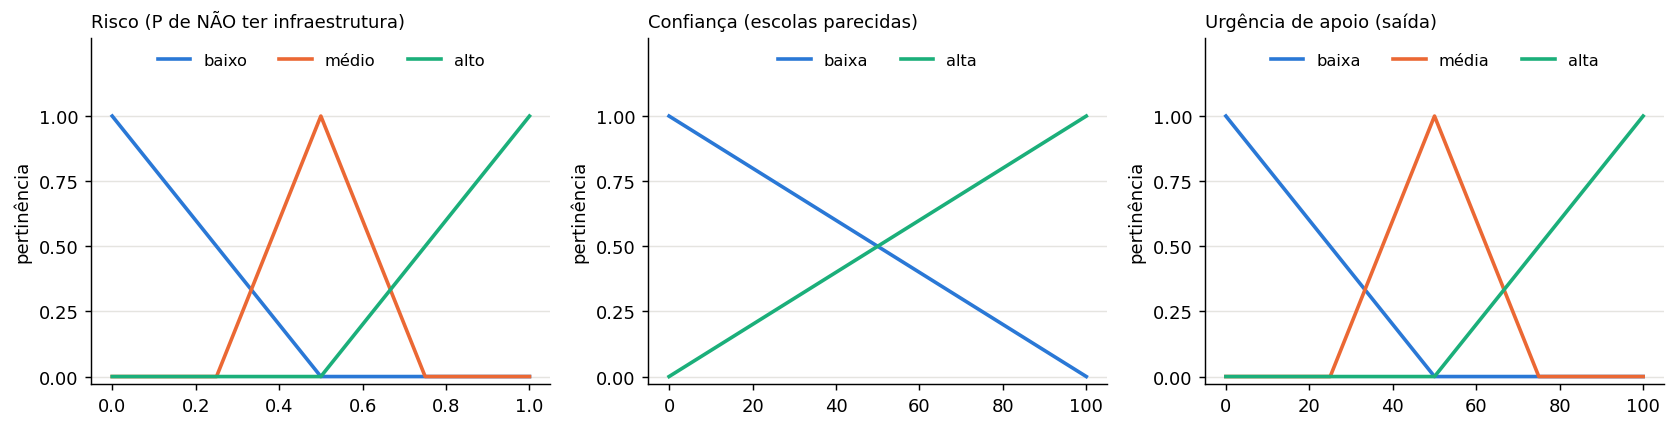

In [2]:
_ = grafico_pertinencia(variaveis, "gráficos/etapa6_pertinencia.png")
plt.show()


O termo **risco médio** está centrado em 0,5. É justamente a fronteira onde a decisão dura vira de lado, então "risco médio" significa "a rede está em dúvida".

**Um cuidado com o exemplo do enunciado.** Lá, `baixo = [0, 0, 0.4]` e `alto = [0.6, 1, 1]` deixam um buraco entre 0,4 e 0,6, onde nenhuma regra dispara e o scikit-fuzzy não consegue calcular a saída. A célula abaixo reproduz o problema. Por isso criamos o termo médio e fizemos os triângulos se cruzarem.

In [3]:
r = ctrl.Antecedent(np.arange(0, 1.01, 0.01), "risco")
u = ctrl.Consequent(np.arange(0, 101, 1), "urgencia")
r["baixo"] = fuzz.trimf(r.universe, [0, 0, 0.4]); r["alto"] = fuzz.trimf(r.universe, [0.6, 1, 1])
u["baixa"] = fuzz.trimf(u.universe, [0, 0, 50]);  u["alta"] = fuzz.trimf(u.universe, [50, 100, 100])
exemplo = ctrl.ControlSystem([ctrl.Rule(r["alto"], u["alta"]), ctrl.Rule(r["baixo"], u["baixa"])])

for valor in (0.75, 0.5):
    simulacao = ctrl.ControlSystemSimulation(exemplo)
    simulacao.input["risco"] = valor
    try:
        simulacao.compute()
        print(f"risco = {valor}: urgência = {simulacao.output['urgencia']:.1f}")
    except KeyError:
        print(f"risco = {valor}: nenhuma regra disparou, o sistema não calcula a saída")

risco = 0.75: urgência = 79.3
risco = 0.5: nenhuma regra disparou, o sistema não calcula a saída


## 3. Regras Se-Então
Escrevemos 3 regras, com os operadores E e OU. No scikit-fuzzy, **E é o mínimo** e **OU é o máximo** das pertinências.

In [4]:
for regra in REGRAS_EM_TEXTO:
    print(regra)

R1: SE risco é ALTO E confiança é ALTA ENTÃO urgência é ALTA
R2: SE risco é MÉDIO OU confiança é BAIXA ENTÃO urgência é MÉDIA
R3: SE risco é BAIXO ENTÃO urgência é BAIXA


- **R1** é o caso claro: a rede acha que provavelmente falta infraestrutura e há muitas escolas parecidas para sustentar isso. Urgência alta.
- **R2** junta duas situações em que o sistema prefere não afirmar nada com força: a rede está em dúvida (risco médio) **ou** há poucas escolas parecidas (confiança baixa). Urgência média, que na prática quer dizer "verificar antes de decidir".
- **R3** é o caso oposto: risco baixo, urgência baixa.

O efeito combinado é que a baixa confiança **puxa a urgência para o meio**: com poucos dados, o sistema não grita "urgente" nem "tudo certo".

## 4. Como o sistema calcula (um exemplo passo a passo)
Pegamos o grupo das escolas **urbanas, estaduais e sem gerador**: 586 escolas, e a rede calcula $P(\text{infra}=1) = 0{,}426$. Logo `risco` = 0,574.

In [5]:
linha = tabela[(tabela.TP_LOCALIZACAO == 1) & (tabela.TP_DEPENDENCIA == 2) & (tabela.IN_ENERGIA_GERADOR_FOSSIL == 0)].iloc[0]
print(f"N = {linha.N:.0f} | P(infra=1) = {linha.P_infra:.4f} | risco = {linha.risco:.4f} | confiança = {linha.confianca:.0f}\n")

pert_risco = {t: float(fuzz.interp_membership(risco.universe, risco[t].mf, linha.risco)) for t in risco.terms}
pert_conf = {t: float(fuzz.interp_membership(confianca.universe, confianca[t].mf, linha.confianca)) for t in confianca.terms}
print("1) Fuzzificação (pertinência de cada termo)")
print("   risco    :", {t: round(v, 3) for t, v in pert_risco.items()})
print("   confiança:", {t: round(v, 3) for t, v in pert_conf.items()})

ativacao = {
    "R1": min(pert_risco["alto"], pert_conf["alta"]),      # E = mínimo
    "R2": max(pert_risco["medio"], pert_conf["baixa"]),    # OU = máximo
    "R3": pert_risco["baixo"],
}
print("\n2) Ativação das regras:", {k: round(v, 3) for k, v in ativacao.items()})
print("\n3) Cada regra corta o triângulo da urgência na sua altura, as regiões são unidas")
print("   e o centroide da região resultante é a saída (defuzzificação).")
simulacao = ctrl.ControlSystemSimulation(sistema)
print(f"\nUrgência = {calcular_urgencia(simulacao, linha.risco, linha.confianca):.2f}  (rótulo: {linha.rotulo_fuzzy})")

N = 586 | P(infra=1) = 0.4256 | risco = 0.5744 | confiança = 100

1) Fuzzificação (pertinência de cada termo)
   risco    : {'baixo': 0.0, 'medio': 0.703, 'alto': 0.149}
   confiança: {'baixa': 0.0, 'alta': 1.0}

2) Ativação das regras: {'R1': 0.149, 'R2': 0.703, 'R3': 0.0}

3) Cada regra corta o triângulo da urgência na sua altura, as regiões são unidas
   e o centroide da região resultante é a saída (defuzzificação).

Urgência = 55.45  (rótulo: media)


A regra R2 dispara com força 0,703 (o risco é "bem médio") e a R1 só com 0,149. O triângulo "média" fica cortado em 0,703 e o "alta" em 0,149. O centroide da união fica um pouco acima de 50, em **55,45**: uma urgência média inclinada para alta. Nenhuma regra decidiu sozinha, e é isso que o limiar duro não consegue expressar.

## 5. Alimentando o sistema com as probabilidades da Etapa 5
Para cada configuração da evidência (localização, rede e gerador), a rede responde $P(\text{infra} \mid \text{evidência})$ por enumeração. Essa probabilidade vira o `risco`, o número de escolas do grupo vira a `confianca`, e o sistema devolve a urgência. A tabela mostra todas as 14 configurações que aparecem no Censo.

In [6]:
nomes = {"TP_LOCALIZACAO": {1: "urbana", 2: "rural"},
         "TP_DEPENDENCIA": {1: "federal", 2: "estadual", 3: "municipal", 4: "privada"},
         "IN_ENERGIA_GERADOR_FOSSIL": {0: "não", 1: "sim"}}
vista = tabela.copy()
for coluna, mapa in nomes.items():
    vista[coluna] = vista[coluna].map(mapa)
vista = vista.rename(columns={"TP_LOCALIZACAO": "localização", "TP_DEPENDENCIA": "rede", "IN_ENERGIA_GERADOR_FOSSIL": "gerador",
                              "P_infra": "P(infra)", "urgencia": "urgência", "rotulo_fuzzy": "rótulo fuzzy",
                              "decisao_dura": "decisão dura", "real_infra": "% real com infra"})
display(vista[["localização", "rede", "gerador", "N", "P(infra)", "risco", "urgência", "rótulo fuzzy", "decisão dura", "% real com infra"]]
        .sort_values("urgência", ascending=False).round(3).reset_index(drop=True))

,localização,rede,gerador,N,P(infra),risco,urgência,rótulo fuzzy,decisão dura,% real com infra
0,rural,municipal,sim,654,0.088,0.912,82.895,alta,sem infra,0.055
1,urbana,municipal,não,893,0.146,0.854,82.236,alta,sem infra,0.348
2,rural,municipal,não,2834,0.146,0.854,82.236,alta,sem infra,0.080
3,urbana,privada,não,385,0.294,0.706,70.846,alta,sem infra,0.377
4,rural,estadual,sim,18,0.287,0.713,56.130,media,sem infra,0.000
5,urbana,estadual,não,586,0.426,0.574,55.454,media,sem infra,0.404
6,rural,estadual,não,153,0.426,0.574,55.454,media,sem infra,0.118
7,rural,privada,não,3,0.294,0.706,51.107,media,sem infra,0.000
8,urbana,privada,sim,15,0.487,0.513,50.954,media,sem infra,0.867
9,urbana,estadual,sim,1,0.287,0.713,50.376,media,sem infra,0.000


**Como ler.** O grupo mais claro é o das escolas rurais e municipais (3.488 escolas, só 7,6% com infraestrutura), que recebe urgência entre **82 e 83 (alta)**.

Os casos interessantes estão na fronteira. As **escolas estaduais urbanas sem gerador** (586) têm $P = 0{,}426$. A decisão dura diz "sem infra" e ponto final, mas na realidade 40,4% delas têm. O fuzzy devolve 55 e o rótulo **média**: "provável que falte, mas verifique".

O grupo das **escolas privadas urbanas com gerador** (N = 15) mostra o limite do modelo: a rede dá 0,487 e na prática 86,7% têm infraestrutura. É a limitação do DAG já apontada na Etapa 5, e o fuzzy não a corrige. O que ele faz é não afirmar nada com força: urgência 51, rótulo "média", confiança 15.

**Um alerta importante.** As linhas "urbana, municipal, sem gerador" (893 escolas) e "rural, municipal, sem gerador" (2.834 escolas) têm exatamente a mesma probabilidade (0,146) e a mesma urgência (82). Só que 34,8% das urbanas têm infraestrutura, contra 8,0% das rurais. O erro não é do fuzzy: dados a rede de ensino e o gerador, o DAG da Etapa 5 não deixa a localização influenciar o alvo (é a d-separação que o diagnóstico extra daquela etapa já havia rejeitado nos dados). O fuzzy herda essa limitação. Uma variante a avaliar na Etapa 5 é incluir a aresta `TP_LOCALIZACAO → infra_digital_basica`, conferindo desempenho fora do treino antes de adotá-la.

## 6. Decisão fuzzy x decisão dura (limiar 0,5)
O gráfico varia a probabilidade da rede de 0 a 1. A linha tracejada é a decisão dura, que salta de 100 para 0 em $P = 0{,}5$. As linhas contínuas são o fuzzy com muitas escolas parecidas (100) e com poucas (10).

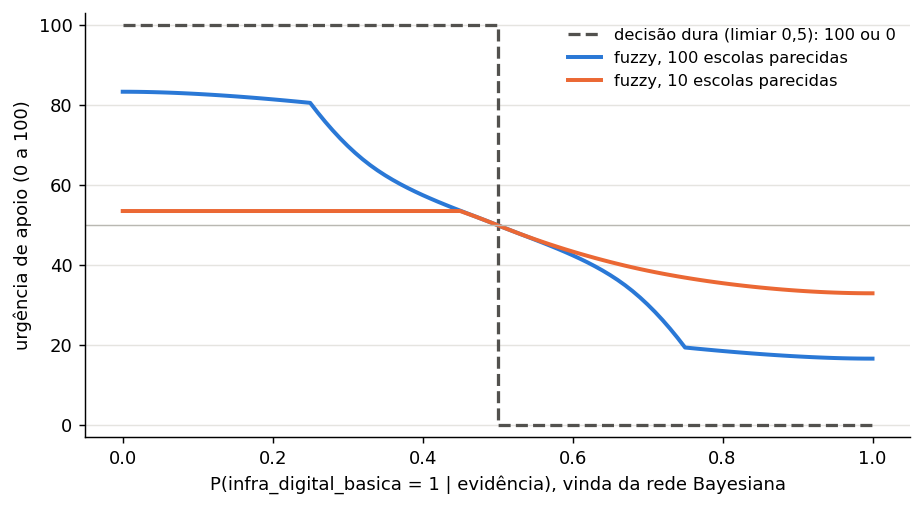

In [7]:
_ = grafico_curva(sistema, "gráficos/etapa6_curva.png")
plt.show()


Duas coisas aparecem no gráfico. Primeiro, o fuzzy muda **de forma suave** perto da fronteira, em vez de pular. Segundo, com 10 escolas parecidas (laranja), a urgência nunca passa de 54 nem cai de 33, por causa da regra R2. Com 100 escolas (azul), o sistema se permite chegar a 83 e a 17. Em $P = 0{,}5$ as duas curvas se encontram em 50, porque ali a dúvida é total, independentemente do N.

**Medindo.** Usamos o mesmo protocolo da Etapa 1: 5-fold estratificado com `random_state=42`. Em cada fold, as CPTs e as contagens vêm só do treino, e as decisões são tomadas nas escolas de teste.

In [8]:
escolas = validacao_cruzada(df, EVIDENCIA_PADRAO, sistema, variaveis, k=5, seed=42)
resumo, por_rotulo, por_dura = comparar_decisoes(escolas)

metricas = pd.DataFrame({
    "acurácia": [resumo["dura"]["acuracia"], resumo["fuzzy"]["acuracia"]],
    "recall sem infra": [resumo["dura"]["recall_sem_infra"], resumo["fuzzy"]["recall_sem_infra"]],
    "recall com infra": [resumo["dura"]["recall_com_infra"], resumo["fuzzy"]["recall_com_infra"]],
}, index=["decisão dura (P >= 0,5)", "fuzzy (urgência >= 50)"])
print(f"Concordância entre as duas decisões sim/não: {resumo['concordancia']:.2%}\n")
display((metricas * 100).round(2).astype(str) + "%")

print("AUC: quão bem cada saída ordena as escolas sem infraestrutura acima das que têm")
display(pd.Series(resumo["auc"], name="AUC").round(3).to_frame())

print("Escolas por rótulo fuzzy, e % das que realmente têm infraestrutura")
display(por_rotulo.rename(columns={"pct_com_infra_real": "% real com infra"}).assign(**{"% real com infra": lambda t: (t["% real com infra"] * 100).round(1)}))
print("Escolas por decisão dura")
display(por_dura.rename(columns={"pct_com_infra_real": "% real com infra"}).assign(**{"% real com infra": lambda t: (t["% real com infra"] * 100).round(1)}))

Concordância entre as duas decisões sim/não: 100.00%

AUC: quão bem cada saída ordena as escolas sem infraestrutura acima das que têm
Escolas por rótulo fuzzy, e % das que realmente têm infraestrutura
Escolas por decisão dura


,acurácia,recall sem infra,recall com infra
"decisão dura (P >= 0,5)",82.29%,99.98%,2.28%
fuzzy (urgência >= 50),82.29%,99.98%,2.28%


,AUC
decisao dura (sim/não),0.511
probabilidade da rede,0.666
urgência fuzzy,0.656


,escolas,% real com infra
rotulo_fuzzy,,
baixa,NaN,NaN
media,796.0,36.1
alta,4766.0,15.1


,escolas,% real com infra
decisao_dura,,
sem infra,5538,17.8
tem infra,24,95.8


**O que os números dizem, sem exagero.**

1. **Na decisão sim/não, o fuzzy não ganha.** Com os limiares usados (P ≥ 0,5 e urgência ≥ 50), as duas decisões coincidem neste conjunto de dados nas 5.562 escolas e a acurácia é a mesma, 82,29%. Isso é só um pouco acima da classe majoritária (81,9%), porque cadastro (localização, rede, gerador) sozinho diz pouco.
2. **O ganho está na informação que o "sim/não" joga fora.** A decisão dura joga 5.538 escolas no mesmo saco "sem infra", e 17,8% delas têm infraestrutura. O fuzzy separa esse saco em **média** (796 escolas, 36,1% com infra) e **alta** (4.766 escolas, 15,1% com infra). Ou seja, o rótulo é ordenado: quanto maior a urgência, menos escolas têm infraestrutura de fato.
3. **O AUC confirma.** A decisão dura (binária) fica em 0,511, quase um sorteio. A urgência fuzzy chega a 0,656, praticamente o mesmo da probabilidade da rede (0,666). O fuzzy **preserva** a ordenação que o limiar destrói, e ainda traz rótulos legíveis e a noção de confiança.
4. **Nenhuma escola fica com rótulo "baixa".** Só com o cadastro, a rede nunca chega perto de garantir que a escola tem infraestrutura (o maior $P$ é 0,64, e com N pequeno).

### Verificação com mais evidência
E se o gestor soubesse também o que a escola tem fisicamente? Usamos como evidência os três pais do alvo na rede (`IN_ENERGIA_GERADOR_FOSSIL`, `IN_LABORATORIO_INFORMATICA`, `IN_BIBLIOTECA`). Nesse caso a rede só consulta a CPT do alvo, e o N de cada grupo é exatamente o N da Etapa 5 (3.358, 581, 205, 724, 636, 32, 8 e 18).

In [9]:
EVIDENCIA_B = ["IN_ENERGIA_GERADOR_FOSSIL", "IN_LABORATORIO_INFORMATICA", "IN_BIBLIOTECA"]
_, _, _, _, tabela_b = executar("dados_etapa1.csv", EVIDENCIA_B)
display(tabela_b[EVIDENCIA_B + ["N", "P_infra", "urgencia", "rotulo_fuzzy", "decisao_dura", "real_infra"]].round(3).reset_index(drop=True))

escolas_b = validacao_cruzada(df, EVIDENCIA_B, sistema, variaveis, k=5, seed=42)
resumo_b, por_rotulo_b, por_dura_b = comparar_decisoes(escolas_b)
print(f"Concordância sim/não: {resumo_b['concordancia']:.2%}")
print(f"Acurácia 5-fold: dura = {resumo_b['dura']['acuracia']:.2%} | fuzzy = {resumo_b['fuzzy']['acuracia']:.2%}")
print("AUC:", {k: round(v, 3) for k, v in resumo_b["auc"].items()})
display(por_rotulo_b.rename(columns={"pct_com_infra_real": "% real com infra"}).assign(**{"% real com infra": lambda t: (t["% real com infra"] * 100).round(1)}))

comparacao = pd.DataFrame({"acurácia": [0.8190, 0.8765, resumo_b["dura"]["acuracia"], resumo_b["fuzzy"]["acuracia"]]},
    index=["classe majoritária (Etapa 1)", "árvore, profundidade 3 (Etapa 1)", "rede Bayesiana + decisão dura", "rede Bayesiana + fuzzy"])
print("\nMesmo protocolo (5-fold estratificado, seed 42):")
display((comparacao * 100).round(2).astype(str) + "%")

Concordância sim/não: 100.00%
Acurácia 5-fold: dura = 87.67% | fuzzy = 87.67%
AUC: {'decisao dura (sim/não)': 0.782, 'probabilidade da rede': 0.816, 'urgência fuzzy': 0.815}

Mesmo protocolo (5-fold estratificado, seed 42):


,IN_ENERGIA_GERADOR_FOSSIL,IN_LABORATORIO_INFORMATICA,IN_BIBLIOTECA,N,P_infra,urgencia,rotulo_fuzzy,decisao_dura,real_infra
0,0,0,0,3358,0.070,83.050,alta,sem infra,0.069
1,0,0,1,581,0.178,81.770,alta,sem infra,0.177
2,0,1,0,205,0.662,36.096,media,tem infra,0.663
3,0,1,1,724,0.664,35.825,media,tem infra,0.664
4,1,0,0,636,0.038,83.246,alta,sem infra,0.036
5,1,0,1,32,0.324,60.359,media,sem infra,0.312
6,1,1,0,8,0.700,38.670,media,tem infra,0.750
7,1,1,1,18,0.800,35.322,media,tem infra,0.833


,escolas,% real com infra
rotulo_fuzzy,,
baixa,NaN,NaN
media,987.0,65.7
alta,4575.0,7.8


,acurácia
classe majoritária (Etapa 1),81.9%
"árvore, profundidade 3 (Etapa 1)",87.65%
rede Bayesiana + decisão dura,87.67%
rede Bayesiana + fuzzy,87.67%


Com laboratório e biblioteca conhecidos, a probabilidade fica longe de 0,5 em quase todos os grupos (de 0,04 a 0,80), e a decisão dura e a fuzzy voltam a **concordar em 100%**, com acurácia de 87,67%, igual à da árvore da Etapa 1 (87,65%). O fuzzy não tem como melhorar um "sim/não" que já é claro. O que ele continua oferecendo é o rótulo **média** para as 987 escolas com laboratório ou com poucos dados, e esse rótulo é fiel à realidade: 65,7% delas têm infraestrutura e 34,3% não têm. A decisão dura, por sua vez, declara "tem infra" para as 955 escolas com laboratório, e 33,2% delas não têm. O AUC sobe de 0,782 (dura) para 0,815 (fuzzy).

## 7. Interpretabilidade
**Cada regra é legível por um especialista?** Sim. As três regras são frases em português que um gestor da Secretaria de Educação lê e discute sem saber o que é uma CPT. Ele pode concordar, discordar ("risco médio deveria bastar para urgência alta") e mudar a regra sem refazer nenhum treinamento. Comparando com as etapas anteriores: a árvore da Etapa 1 também é legível, mas decide por cortes rígidos, e as tabelas da rede Bayesiana são números que só quem estuda probabilidade interpreta bem.

**O que o especialista precisa checar.** A parte arbitrária está nos triângulos: os pontos 0,25, 0,5 e 0,75 do risco e o "100 escolas" da confiança foram escolhidos por nós, não aprendidos dos dados. Um especialista deve validar esses pontos. E a urgência é uma **prioridade ordinal**, não uma probabilidade: 83 não quer dizer "83% de chance". Como o centroide encolhe a faixa de saída, a urgência só vai de cerca de 17 a 83.

**Quando o fuzzy supera o limiar rígido?** Neste experimento, em três situações:
- **Fronteira ambígua:** grupos com $P$ perto de 0,5 (como as 586 escolas estaduais urbanas, com 40% de infraestrutura real) recebem "média" em vez de um "sim/não" que erra 40% das vezes.
- **Poucos dados:** a confiança baixa puxa a urgência para o meio, em vez de afirmar com força algo que se apoia em 8 ou 15 escolas.
- **Priorização:** o fuzzy mantém uma ordenação (AUC de 0,656 contra 0,511) que o limiar apaga.

**Quando não supera?** Quando a probabilidade já está longe de 0,5 e há muitos dados, como na verificação com laboratório e biblioteca: as decisões coincidem e a acurácia é a mesma.

## 8. Integração final do pipeline
O diagrama resume como as etapas se conectam neste repositório. As setas contínuas são o fluxo principal. As tracejadas mostram o que é reaproveitado de etapas mais antigas.

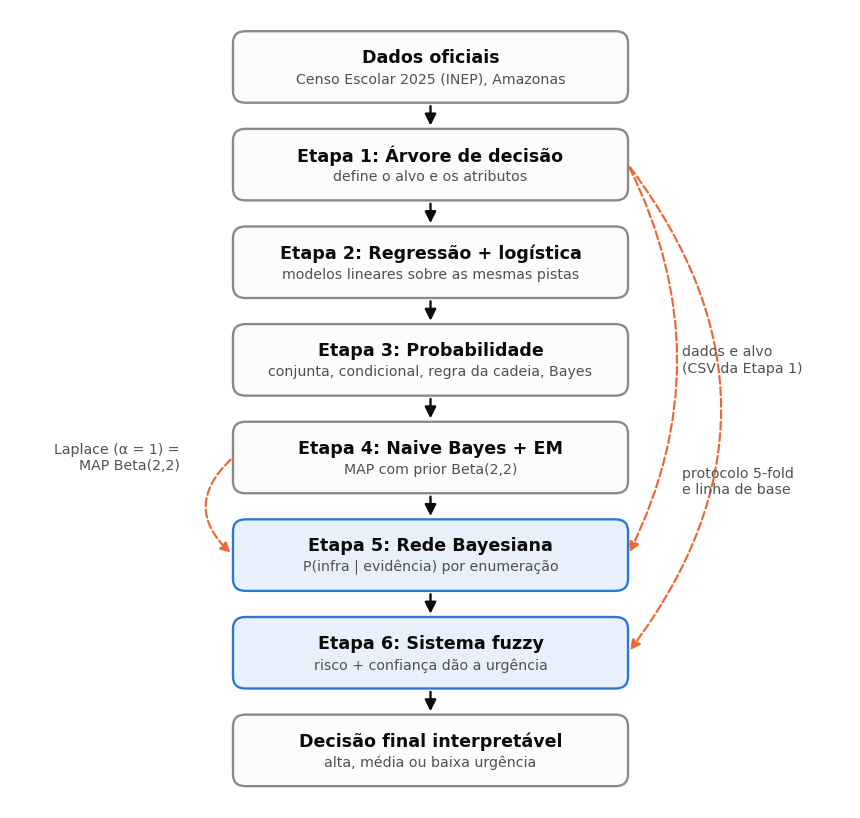

In [10]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

etapas = [
    ("Dados oficiais", "Censo Escolar 2025 (INEP), Amazonas"),
    ("Etapa 1: Árvore de decisão", "define o alvo e os atributos"),
    ("Etapa 2: Regressão + logística", "modelos lineares sobre as mesmas pistas"),
    ("Etapa 3: Probabilidade", "conjunta, condicional, regra da cadeia, Bayes"),
    ("Etapa 4: Naive Bayes + EM", "MAP com prior Beta(2,2)"),
    ("Etapa 5: Rede Bayesiana", "P(infra | evidência) por enumeração"),
    ("Etapa 6: Sistema fuzzy", "risco + confiança dão a urgência"),
    ("Decisão final interpretável", "alta, média ou baixa urgência"),
]
fig, ax = plt.subplots(figsize=(9, 8.6), dpi=120)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
x0, larg, alt = 0.27, 0.46, 0.078
ys = np.linspace(0.93, 0.07, len(etapas))
for i, ((titulo, nota), y) in enumerate(zip(etapas, ys)):
    destaque = i in (5, 6)
    ax.add_patch(FancyBboxPatch((x0, y - alt / 2), larg, alt, boxstyle="round,pad=0.006,rounding_size=0.015",
                                linewidth=1.4, edgecolor="#2a78d6" if destaque else "#8a8983",
                                facecolor="#e8f0fb" if destaque else "#fcfcfb"))
    ax.text(0.5, y + 0.012, titulo, ha="center", va="center", fontsize=10.5, fontweight="bold", color="#0b0b0b")
    ax.text(0.5, y - 0.015, nota, ha="center", va="center", fontsize=8.5, color="#52514e")
for i in range(len(etapas) - 1):
    ax.add_patch(FancyArrowPatch((0.5, ys[i] - alt / 2 - 0.006), (0.5, ys[i + 1] + alt / 2 + 0.006),
                                 arrowstyle="-|>", mutation_scale=14, linewidth=1.4, color="#0b0b0b"))

def tracejada(i_de, i_para, lado, raio, texto, y_texto):
    xa = x0 + larg + 0.006 if lado == "dir" else x0 - 0.006
    ax.add_patch(FancyArrowPatch((xa, ys[i_de]), (xa, ys[i_para]), arrowstyle="-|>", mutation_scale=12,
                                 linewidth=1.3, linestyle="--", color="#eb6834",
                                 connectionstyle=f"arc3,rad={raio}"))
    ax.text(0.80 if lado == "dir" else 0.20, y_texto, texto, ha="left" if lado == "dir" else "right",
            va="center", fontsize=8.5, color="#52514e")

tracejada(1, 5, "dir", -0.25, "dados e alvo\n(CSV da Etapa 1)", ys[3])
tracejada(1, 6, "dir", -0.38, "protocolo 5-fold\ne linha de base", ys[4] - 0.03)
tracejada(4, 5, "esq", 0.55, "Laplace (α = 1) =\nMAP Beta(2,2)", ys[4] + 0.0)
plt.show()

## Conclusão da Etapa 6
Construímos um sistema fuzzy Mamdani com 3 variáveis linguísticas, funções de pertinência triangulares e 3 regras com E e OU, alimentado direto pela inferência por enumeração da Etapa 5. A decisão final deixou de ser um "sim/não" e passou a ser uma urgência de 0 a 100 com rótulo (baixa, média, alta) e com consciência de quantos dados sustentam cada probabilidade.

O resultado é honesto e deve ser dito assim no relatório: **o fuzzy não melhora a acurácia da decisão sim/não**, porque usa o mesmo limiar de 0,5. O ganho está em **não jogar fora a informação intermediária**: o AUC passa de 0,511 para 0,656 com o cadastro, o rótulo "média" separa os grupos duvidosos dos claros (36% contra 15% de escolas com infraestrutura), e cada regra pode ser lida e discutida por quem conhece a rede de ensino.

Limitações a registrar: os triângulos são escolhas nossas e não foram ajustados aos dados; a urgência é uma prioridade ordinal, não uma probabilidade; e os erros do DAG apontados na Etapa 5 (falta de `TP_LOCALIZACAO → infra_digital_basica`, por exemplo) passam direto para o fuzzy.

## Integração operacional adicional: árvore, NB, rede e fuzzy
Nesta demonstração, todas as cinco pistas estão disponíveis. Treinamos árvore, NB e CPTs somente nos 70% de treino estratificado. A probabilidade do NB modula a confiança fuzzy por `min(N,100) * (1 - abs(P_NB - P_rede))`; discordância entre árvore e rede encaminha a ação final para revisão. É uma heurística de decisão, não confiança estatística nem melhoria comprovada de acurácia. Os resultados anteriores de 5-fold permanecem referentes ao sistema original.

In [11]:
from integracao import executar_integracao
integrado = executar_integracao()
display(integrado.head(10))
print(integrado.acao_final.value_counts())
print("Escolas de teste:", len(integrado))

acao_final
alta                   1271
media                   383
revisar divergência      15
Name: count, dtype: int64
Escolas de teste: 1669


,CO_ENTIDADE,infra_digital_basica,IN_LABORATORIO_INFORMATICA,IN_BIBLIOTECA,TP_LOCALIZACAO,TP_DEPENDENCIA,IN_ENERGIA_GERADOR_FOSSIL,P_infra,P_NB,classe_arvore,confianca_integrada,urgencia_integrada,acao_final
0,13086448,0,0.0,0.0,2,3,0.0,0.071671,0.012856,0,94.118463,80.447217,alta
1,13040642,0,0.0,0.0,2,3,0.0,0.071671,0.012856,0,94.118463,80.447217,alta
2,13068504,0,0.0,1.0,1,3,0.0,0.193853,0.405043,0,72.570579,71.141556,alta
3,13109162,0,0.0,0.0,2,3,0.0,0.071671,0.012856,0,94.118463,80.447217,alta
4,13030450,1,1.0,1.0,1,2,0.0,0.654832,0.976923,1,67.790964,36.973840,media
5,13108077,0,0.0,0.0,2,3,0.0,0.071671,0.012856,0,94.118463,80.447217,alta
6,13042793,0,0.0,0.0,2,3,1.0,0.036866,0.004244,0,96.737725,81.790154,alta
7,13054384,0,0.0,0.0,2,3,0.0,0.071671,0.012856,0,94.118463,80.447217,alta
8,13109391,0,0.0,0.0,2,3,0.0,0.071671,0.012856,0,94.118463,80.447217,alta
9,13110616,0,0.0,0.0,2,3,0.0,0.071671,0.012856,0,94.118463,80.447217,alta
